# E1 · Pronóstico mensual de TEU del Puerto de Manzanillo

**Karol Gabriel Morán Aréchiga · Data Statistician**  
Equipo con Emilio Rodrigo Ayala Reynoso, Data Engineer y Quality Lead de E1.

Pregunta: ¿cuántos TEU moverá el puerto el mes siguiente al último publicado y en qué temporadas se concentra la actividad?

Se leen exclusivamente Oro y sus parámetros. El corte de limpieza determina entrenamiento y seis meses de prueba; ninguna elección de transformación, descomposición u orden SARIMA utiliza esos seis valores. La elección final entre familias sí usa ese bloque: su error sirve para seleccionar, no constituye una segunda evaluación independiente. Regla fijada en E0: **menor MAPE**, con RMSE y MAE como desempate.

La ejecución exporta el contrato que utiliza el tablero de Emilio. No descarga datos, modifica limpieza, registra horas PSP ni mueve etiquetas Git.

In [1]:
import hashlib
import importlib.metadata
import itertools
import json
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator
from scipy.signal import lfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, adfuller, pacf

RAIZ = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/oro/mensual_integrado.csv").exists()
)
FIGURAS = RAIZ / "docs/E1/figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
SEED = 4434
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.20,
        "font.size": 10,
    }
)
AZUL, NARANJA = "#176b96", "#c76b2b"


def guardar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


ruta_datos = RAIZ / "data/oro/mensual_integrado.csv"
ruta_parametros = RAIZ / "data/oro/parametros_transformacion.json"
datos = pd.read_csv(ruta_datos, parse_dates=["fecha"]).set_index("fecha").sort_index().asfreq("MS")
parametros_limpieza = json.loads(ruta_parametros.read_text(encoding="utf-8"))
corte = pd.Timestamp(parametros_limpieza["ajuste_hasta"])
columnas = ["teu_total", "buques_contenerizada", "fix_promedio_mxn_usd"]
assert datos.index.is_unique and datos[columnas].notna().all().all()
assert datos.index.equals(
    pd.date_range(datos.index.min(), datos.index.max(), freq="MS", name="fecha")
)
assert np.isfinite(datos[columnas].to_numpy()).all() and datos.teu_total.gt(0).all()
assert (datos.index <= corte).tolist() == datos.particion.eq("entrenamiento").tolist()
y = datos.teu_total.astype(float)
train, test = y.loc[:corte], y.loc[y.index > corte]
assert len(test) == 6 and len(train) >= 36
print(f"Objetivo: teu_total (TEU). {len(y)} meses: {y.index.min():%Y-%m} a {y.index.max():%Y-%m}.")
print(
    f"Entrenamiento: {len(train)} meses hasta {corte:%Y-%m}; prueba: {test.index.min():%Y-%m} a {test.index.max():%Y-%m}."
)
print(
    "Versiones:",
    {
        p: importlib.metadata.version(p)
        for p in ["statsmodels", "pandas", "numpy", "scipy", "matplotlib"]
    },
)

Objetivo: teu_total (TEU). 70 meses: 2021-01 a 2026-10.
Entrenamiento: 64 meses hasta 2026-04; prueba: 2026-05 a 2026-10.
Versiones: {'statsmodels': '0.15.0', 'pandas': '3.0.5', 'numpy': '2.5.2', 'scipy': '1.18.1', 'matplotlib': '3.11.1'}


## 1. Caracterización

La serie completa se muestra para descripción. La franja naranja corresponde a prueba y no se emplea en las decisiones de los apartados 2–5. Una media móvil de doce meses ayuda a visualizar evolución lenta; no demuestra por sí misma tendencia causal ni una ruptura estructural. Los años incompletos se identifican por su número de meses.

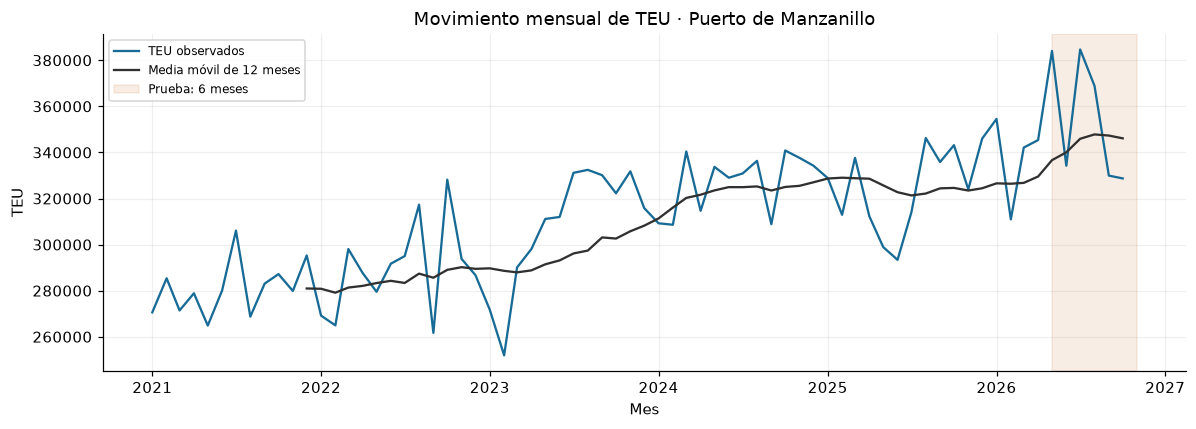

,meses,media_teu,minimo_teu,maximo_teu
fecha,,,,
2021,12,280953.2,264871.0,306075.0
2022,12,289487.7,261672.0,328184.0
2023,12,308215.2,251937.0,332442.0
2024,12,327041.8,308613.0,340837.0
2025,12,324446.6,293385.0,346253.0
2026,10,348349.9,310950.0,384691.0


**Interpretación.** En entrenamiento la recta descriptiva cambia 1,086 TEU por mes.
La serie observada va de 251,937 TEU (2023-02) a 384,691 (2026-07).
Las variaciones interanuales oscilan entre -10.8% y 28.5%:
la trayectoria no es una tasa de crecimiento constante. La estacionalidad se estudia debajo.
Con 5.8 años no se identifica de forma fiable un ciclo económico plurianual independiente
de la tendencia y la estacionalidad. Los cambios de nivel o picos visibles son **señales para investigar**,
no rupturas estructurales confirmadas ni efectos atribuibles a una causa concreta.

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y, color=AZUL, label="TEU observados")
ax.plot(
    y.index, y.rolling(12, min_periods=12).mean(), color="#303030", label="Media móvil de 12 meses"
)
ax.axvspan(
    test.index.min(),
    test.index.max() + pd.offsets.MonthEnd(),
    color=NARANJA,
    alpha=0.12,
    label="Prueba: 6 meses",
)
ax.set(title="Movimiento mensual de TEU · Puerto de Manzanillo", ylabel="TEU", xlabel="Mes")
ax.legend(loc="upper left", fontsize=8)
guardar_figura(fig, "pronostico_01_serie.png")
anual = y.groupby(y.index.year).agg(["count", "mean", "min", "max"])
anual.columns = ["meses", "media_teu", "minimo_teu", "maximo_teu"]
display(anual.round(1))
pendiente = float(np.polyfit(np.arange(len(train)), train, 1)[0])
variacion = y.pct_change(12).dropna()
caracterizacion = {
    "pendiente_lineal_entrenamiento_teu_mes": pendiente,
    "minimo_fecha": y.idxmin().strftime("%Y-%m"),
    "minimo_teu": float(y.min()),
    "maximo_fecha": y.idxmax().strftime("%Y-%m"),
    "maximo_teu": float(y.max()),
    "variacion_interanual_min_pct": float(100 * variacion.min()),
    "variacion_interanual_max_pct": float(100 * variacion.max()),
}
display(
    Markdown(f"""**Interpretación.** En entrenamiento la recta descriptiva cambia {pendiente:,.0f} TEU por mes.
La serie observada va de {y.min():,.0f} TEU ({y.idxmin():%Y-%m}) a {y.max():,.0f} ({y.idxmax():%Y-%m}).
Las variaciones interanuales oscilan entre {100 * variacion.min():.1f}% y {100 * variacion.max():.1f}%:
la trayectoria no es una tasa de crecimiento constante. La estacionalidad se estudia debajo.
Con {len(y) / 12:.1f} años no se identifica de forma fiable un ciclo económico plurianual independiente
de la tendencia y la estacionalidad. Los cambios de nivel o picos visibles son **señales para investigar**,
no rupturas estructurales confirmadas ni efectos atribuibles a una causa concreta.""")
)

## 2. Descomposición aditiva frente a multiplicativa · periodo 12

Ambas descomposiciones se ajustan solo a entrenamiento. Se compara el RMSE de reconstrucción **en TEU y sobre los mismos meses interiores** (sin extremos donde falta la tendencia centrada); no se compara directamente la varianza de un residuo en TEU con la de un cociente adimensional. Es una comparación descriptiva dentro de muestra, distinta del error de pronóstico.

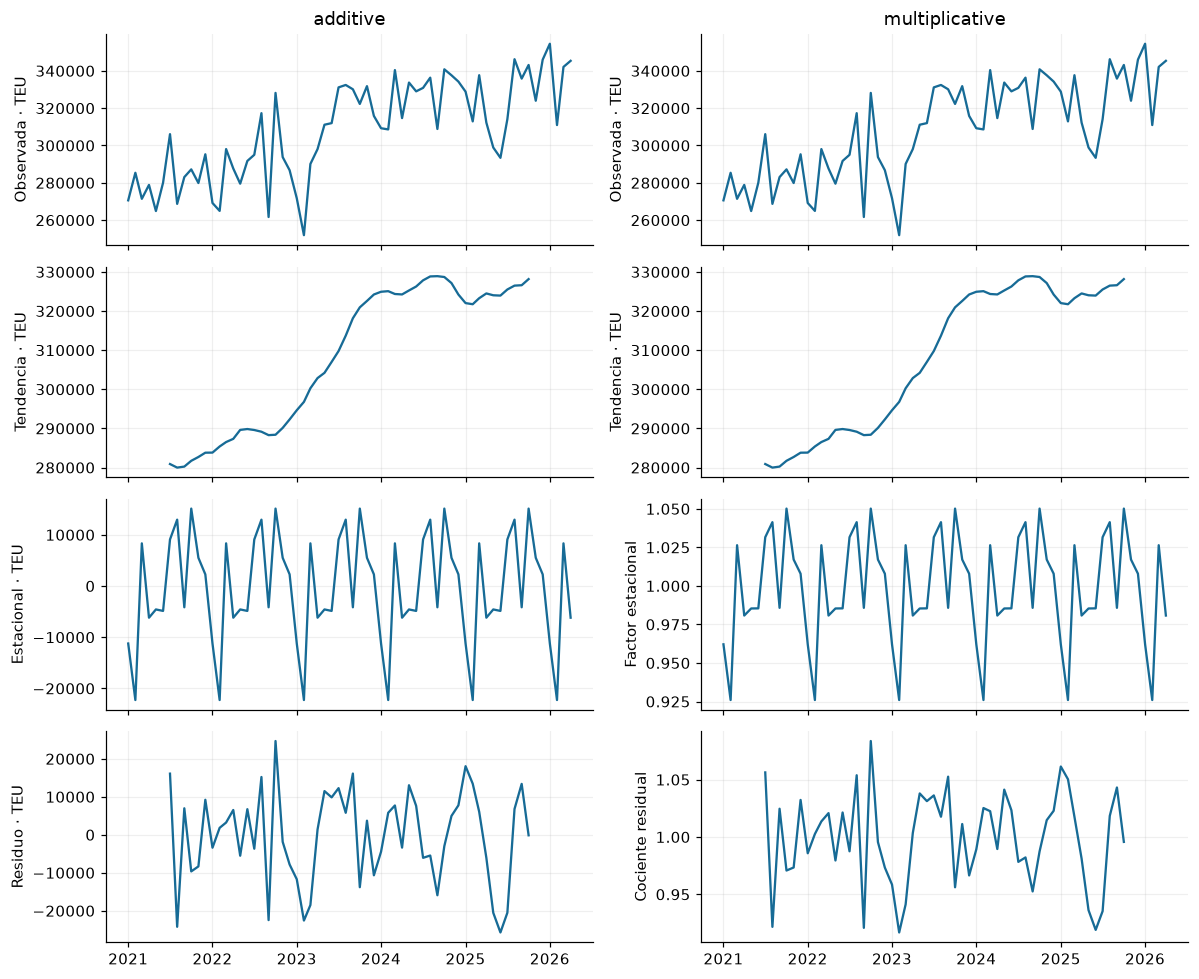

,RMSE_reconstruccion_TEU,meses_comparables
descomposicion,,
additive,12219.41,52
multiplicative,12339.83,52


,componente_estacional
fecha,
1,-11227.91
2,-22268.17
3,8332.88
4,-6188.80
5,-4575.85
6,-4864.38
7,9087.18
8,12955.09
9,-4154.65


**Elección:** additive, por menor error comparable de reconstrucción en entrenamiento
(12,219.4 TEU).
El componente estacional tiene máximo en el mes 10 y mínimo en 2.
La diferencia de ajuste entre formas es pequeña y no demuestra que la amplitud estacional sea fija para siempre.
La aditiva expresa fluctuaciones en TEU y la multiplicativa proporciones del nivel.
Holt-Winters usará esta forma y se evaluará fuera de entrenamiento; no se elige por la gráfica de prueba.

In [3]:
descomposiciones = {
    m: seasonal_decompose(train, model=m, period=12) for m in ["additive", "multiplicative"]
}
filas_decomp = []
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex=True)
for j, (nombre, dec) in enumerate(descomposiciones.items()):
    ajustada = dec.trend + dec.seasonal if nombre == "additive" else dec.trend * dec.seasonal
    interior = ajustada.notna()
    rmse = float(np.sqrt(np.mean((train[interior] - ajustada[interior]) ** 2)))
    filas_decomp.append(
        {
            "descomposicion": nombre,
            "RMSE_reconstruccion_TEU": rmse,
            "meses_comparables": int(interior.sum()),
        }
    )
    for i, (serie, etiqueta) in enumerate(
        [
            (train, "Observada · TEU"),
            (dec.trend, "Tendencia · TEU"),
            (dec.seasonal, "Estacional · TEU" if j == 0 else "Factor estacional"),
            (dec.resid, "Residuo · TEU" if j == 0 else "Cociente residual"),
        ]
    ):
        axes[i, j].plot(serie.index, serie, color=AZUL)
        axes[i, j].set_ylabel(etiqueta)
    axes[0, j].set_title(nombre)
guardar_figura(fig, "pronostico_02_descomposicion.png")
tabla_decomp = pd.DataFrame(filas_decomp).set_index("descomposicion")
display(tabla_decomp.round(2))
descomp_elegida = tabla_decomp.RMSE_reconstruccion_TEU.idxmin()
estacional_ets = "add" if descomp_elegida == "additive" else "mul"
perfil = descomposiciones[descomp_elegida].seasonal.groupby(train.index.month).mean()
display(perfil.rename("componente_estacional").to_frame().round(2))
display(
    Markdown(f"""**Elección:** {descomp_elegida}, por menor error comparable de reconstrucción en entrenamiento
({tabla_decomp.loc[descomp_elegida, "RMSE_reconstruccion_TEU"]:,.1f} TEU).
El componente estacional tiene máximo en el mes {int(perfil.idxmax())} y mínimo en {int(perfil.idxmin())}.
La diferencia de ajuste entre formas es pequeña y no demuestra que la amplitud estacional sea fija para siempre.
La aditiva expresa fluctuaciones en TEU y la multiplicativa proporciones del nivel.
Holt-Winters usará esta forma y se evaluará fuera de entrenamiento; no se elige por la gráfica de prueba.""")
)

## 3. Estacionariedad · Dickey-Fuller aumentada

Hipótesis nula ADF: raíz unitaria. Se muestran constante y, como sensibilidad, tendencia determinista en niveles; después diferencias regular, estacional y combinada. El máximo de rezagos es 12 y el rezago efectivo se selecciona por AIC. Se prefiere la menor pérdida de observaciones que rechace al 5%, evitando diferenciar por rutina. Rechazar raíz unitaria no demuestra todos los supuestos de estacionariedad ni homocedasticidad.

Para la regla SARIMA se toma como referencia la versión con constante; la versión con tendencia se informa como sensibilidad. Si esta última rechaza en niveles, también es plausible una descripción estacionaria alrededor de tendencia determinista. No se interpreta d=1 como prueba de que el proceso sea necesariamente integrado: se usa una diferencia mensual parsimoniosa para no imponer extrapolación de una tendencia lineal fija.

In [4]:
transformaciones = {
    "nivel_c": (train, "c"),
    "nivel_ct": (train, "ct"),
    "d1": (train.diff().dropna(), "c"),
    "D1_12": (train.diff(12).dropna(), "c"),
    "d1_D1_12": (train.diff().diff(12).dropna(), "c"),
}
filas_adf = []
for nombre, (serie, regresion) in transformaciones.items():
    resultado = adfuller(serie, maxlag=12, regression=regresion, autolag="AIC", result_object=False)
    filas_adf.append(
        {
            "transformacion": nombre,
            "ADF": float(resultado[0]),
            "p_valor": float(resultado[1]),
            "rezagos": int(resultado[2]),
            "n_util": int(resultado[3]),
            "regresion": regresion,
            "critico_5pct": float(resultado[4]["5%"]),
        }
    )
tabla_adf = pd.DataFrame(filas_adf).set_index("transformacion")
display(tabla_adf)
if tabla_adf.loc["nivel_c", "p_valor"] < 0.05:
    d_sarima, D_sarima, serie_estacionaria = 0, 0, train
elif tabla_adf.loc["d1", "p_valor"] < 0.05:
    d_sarima, D_sarima, serie_estacionaria = 1, 0, train.diff().dropna()
elif tabla_adf.loc["D1_12", "p_valor"] < 0.05:
    d_sarima, D_sarima, serie_estacionaria = 0, 1, train.diff(12).dropna()
else:
    assert tabla_adf.loc["d1_D1_12", "p_valor"] < 0.05, (
        "ADF no respalda ninguna transformación propuesta"
    )
    d_sarima, D_sarima, serie_estacionaria = 1, 1, train.diff().diff(12).dropna()
display(
    Markdown(f"""Se utiliza **d={d_sarima}, D={D_sarima}** para SARIMA.
La tabla permite ver que añadir otra diferencia no garantiza mejorar el ADF: puede perder potencia o sobrediferenciar.
D=0 no elimina la estacionalidad determinista; los términos estacionales P y Q todavía pueden modelar dependencia a 12 meses.""")
)

,ADF,p_valor,rezagos,n_util,regresion,critico_5pct
transformacion,,,,,,
nivel_c,-1.994840,2.888404e-01,1,62,c,-2.909427
nivel_ct,-6.340762,4.108900e-07,0,63,ct,-3.482637
d1,-5.008093,2.138904e-05,6,56,c,-2.914731
D1_12,-1.992082,2.900556e-01,12,39,c,-2.939109
d1_D1_12,-1.657457,4.531544e-01,11,39,c,-2.939109


Se utiliza **d=1, D=0** para SARIMA.
La tabla permite ver que añadir otra diferencia no garantiza mejorar el ADF: puede perder potencia o sobrediferenciar.
D=0 no elimina la estacionalidad determinista; los términos estacionales P y Q todavía pueden modelar dependencia a 12 meses.

## 4. ACF/PACF y correlaciones cruzadas

ACF/PACF se examinan en niveles y en la transformación seleccionada, con hasta 24 rezagos. Sus bandas son puntuales y exploratorias. Para la correlación cruzada se usa únicamente entrenamiento: primero diferencias mensuales, luego preblanqueo de cada predictor con AR(0…6), elegido por AIC con el mismo `hold_back=6`. El mismo filtro se aplica a ΔTEU.

Convención: **r(k) = corr(ΔTEU_t filtrado, ΔX_{t−k} filtrado)**. Un k positivo significa que X precede a TEU; k=0 es contemporáneo; un k negativo no sirve como anticipación. Los p-valores de Pearson son aproximados tras el preblanqueo y se corrigen por Holm conjuntamente en los 50 contrastes (dos predictores × 25 rezagos). No son pruebas causales ni justifican utilizar valores futuros de un predictor.

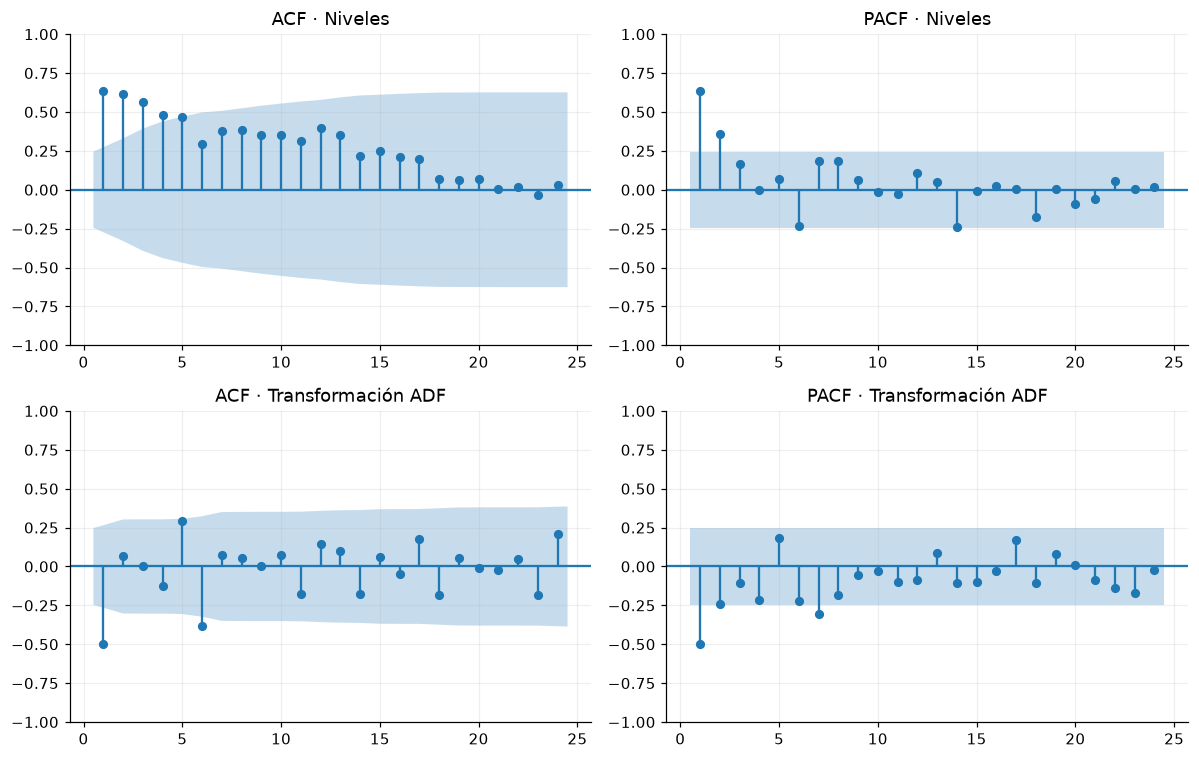

Rezagos fuera de bandas puntuales en la serie transformada: **ACF [1, 6]; PACF [1, 7]**.
Un corte o decaimiento en rezagos cortos orienta los términos AR/MA; la señal cercana a 12 orienta P/Q.
No se traduce cada pico en un parámetro: la búsqueda acotada por AIC del siguiente apartado verifica candidatos parsimoniosos.

,orden_ar,AIC,n_filtrado
buques_contenerizada,2.0,400.383503,57.0
fix_promedio_mxn_usd,2.0,59.693802,57.0


,variable,rezago,correlacion,n_pares,p_nominal,p_holm,significativo_holm
12,buques_contenerizada,0,0.68317,57,0.0,0.0,True


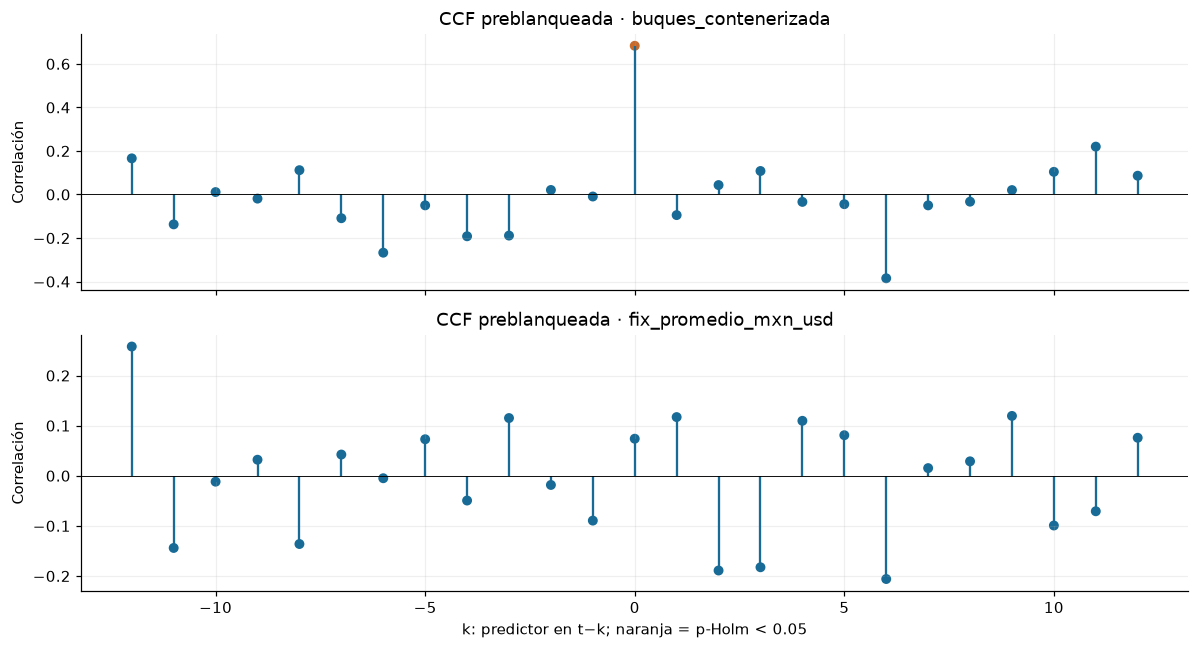

**Interpretación:** los rezagos que superan Holm aparecen en la tabla. Los de k≤0 son asociación contemporánea o posterior; solo k>0 ofrece una señal temporal de anticipación, todavía exploratoria. Las cuatro familias de pronóstico serán univariadas: no requerirán conocer buques ni FIX futuros.

La ACF transformada en lag 1 es -0.499 y la PACF en lag 1 es -0.499: hay dependencia corta negativa. En lag 12 son 0.142 y -0.086; el gráfico no obliga a introducir un término estacional. Los picos aislados de 6/7 se consideran exploratorios, no prueba de un ciclo semestral.

In [5]:
nlags = min(24, len(serie_estacionaria) // 2 - 1)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, (serie, titulo) in enumerate(
    [(train, "Niveles"), (serie_estacionaria, "Transformación ADF")]
):
    plot_acf(serie, lags=nlags, zero=False, ax=axes[i, 0], title=f"ACF · {titulo}")
    plot_pacf(serie, lags=nlags, zero=False, method="ywm", ax=axes[i, 1], title=f"PACF · {titulo}")
guardar_figura(fig, "pronostico_03_acf_pacf.png")
val_acf, ic_acf = acf(serie_estacionaria, nlags=nlags, alpha=0.05, result_object=False)
val_pacf, ic_pacf = pacf(
    serie_estacionaria, nlags=nlags, method="ywm", alpha=0.05, result_object=False
)
lags_acf = [int(k) for k in range(1, nlags + 1) if ic_acf[k, 0] > 0 or ic_acf[k, 1] < 0]
lags_pacf = [int(k) for k in range(1, nlags + 1) if ic_pacf[k, 0] > 0 or ic_pacf[k, 1] < 0]
display(
    Markdown(f"""Rezagos fuera de bandas puntuales en la serie transformada: **ACF {lags_acf}; PACF {lags_pacf}**.
Un corte o decaimiento en rezagos cortos orienta los términos AR/MA; la señal cercana a 12 orienta P/Q.
No se traduce cada pico en un parámetro: la búsqueda acotada por AIC del siguiente apartado verifica candidatos parsimoniosos.""")
)


def preblanquear(x, objetivo):
    centrada = x - x.mean()
    n_comun = len(x) - 6
    var = float(np.mean(centrada.iloc[6:] ** 2))
    candidatos = [(0, n_comun * (np.log(2 * np.pi * var) + 1) + 2, np.array([]))]
    for orden in range(1, 7):
        ar = AutoReg(centrada, lags=orden, trend="n", hold_back=6).fit()
        candidatos.append((orden, float(ar.aic), np.asarray(ar.params)))
    orden, aic, coef = min(candidatos, key=lambda z: z[1])
    filtro = np.r_[1.0, -coef]
    xx = pd.Series(lfilter(filtro, [1.0], centrada), index=x.index).iloc[6:]
    yy = pd.Series(lfilter(filtro, [1.0], objetivo - objetivo.mean()), index=objetivo.index).iloc[
        6:
    ]
    return xx, yy, {"orden_ar": int(orden), "AIC": float(aic), "n_filtrado": len(xx)}


filas_ccf, filtros = [], {}
for variable in ["buques_contenerizada", "fix_promedio_mxn_usd"]:
    x = datos.loc[train.index, variable].diff().dropna()
    xx, yy, filtros[variable] = preblanquear(x, train.diff().dropna())
    for k in range(-12, 13):
        pares = pd.concat([yy.rename("y"), xx.shift(k).rename("x")], axis=1).dropna()
        rho, p = st.pearsonr(pares.y, pares.x)
        filas_ccf.append(
            {
                "variable": variable,
                "rezago": k,
                "correlacion": float(rho),
                "n_pares": len(pares),
                "p_nominal": float(p),
            }
        )
tabla_ccf = pd.DataFrame(filas_ccf)
rechazar_h0, p_holm, _, _ = multipletests(tabla_ccf.p_nominal, alpha=0.05, method="holm")
tabla_ccf["p_holm"] = p_holm
tabla_ccf["significativo_holm"] = rechazar_h0
display(pd.DataFrame(filtros).T)
display(tabla_ccf.loc[tabla_ccf.significativo_holm].round(5))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (variable, grupo) in zip(axes, tabla_ccf.groupby("variable", sort=False)):
    ax.vlines(grupo.rezago, 0, grupo.correlacion, color=AZUL)
    ax.scatter(
        grupo.rezago, grupo.correlacion, c=np.where(grupo.significativo_holm, NARANJA, AZUL), s=30
    )
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set(title=f"CCF preblanqueada · {variable}", ylabel="Correlación")
axes[-1].set_xlabel("k: predictor en t−k; naranja = p-Holm < 0.05")
guardar_figura(fig, "pronostico_04_correlacion_cruzada.png")
significativos = tabla_ccf.loc[
    tabla_ccf.significativo_holm, ["variable", "rezago", "correlacion", "p_holm"]
]
display(
    Markdown(
        "**Interpretación:** "
        + (
            "no se detectan rezagos significativos después de Holm; esto no demuestra ausencia de asociación."
            if significativos.empty
            else "los rezagos que superan Holm aparecen en la tabla. Los de k≤0 son asociación contemporánea o posterior; solo k>0 ofrece una señal temporal de anticipación, todavía exploratoria."
        )
        + " Las cuatro familias de pronóstico serán univariadas: no requerirán conocer buques ni FIX futuros."
    )
)
display(
    Markdown(
        f"La ACF transformada en lag 1 es {val_acf[1]:.3f} y la PACF en lag 1 es {val_pacf[1]:.3f}: hay dependencia corta negativa. En lag 12 son {val_acf[12]:.3f} y {val_pacf[12]:.3f}; el gráfico no obliga a introducir un término estacional. Los picos aislados de 6/7 se consideran exploratorios, no prueba de un ciclo semestral."
    )
)

## 5. SES, Holt, Holt-Winters y SARIMA

SES = ETS(A,N,N), Holt = ETS(A,A,N), Holt-Winters = ETS con error aditivo, tendencia aditiva y estacionalidad elegida en el apartado 2. Son las tres formas clásicas estimadas en el marco ETS por máxima verosimilitud. Se trabaja en miles de TEU para acondicionar el cálculo, restituyendo TEU antes de medir o exportar.

SARIMA mantiene d/D del diagnóstico y periodo 12. Se prueban p,q∈{0,1,2}, P,Q∈{0,1}, con p+q+P+Q≤3 para contener complejidad en 64 meses. Todos usan la misma serie, d/D y tendencia constante (deriva cuando d=1). Gana el menor AIC entre candidatos convergentes y finitos. Se registran los fallos y advertencias; AIC elige dentro de SARIMA, **no reemplaza** la selección final por error fuera de entrenamiento.

In [6]:
def ajustar_ets(serie, tendencia=None, estacionalidad=None):
    ajuste = ETSModel(
        serie / 1000,
        error="add",
        trend=tendencia,
        seasonal=estacionalidad,
        seasonal_periods=12 if estacionalidad else None,
    ).fit(disp=False, maxiter=2000)
    assert ajuste.mle_retvals.get("converged", True), "ETS no convergió"
    return ajuste


ajustes = {
    "SES": ajustar_ets(train),
    "Holt": ajustar_ets(train, "add"),
    "Holt-Winters": ajustar_ets(train, "add", estacional_ets),
}
filas_sarima, candidatos_sarima = [], {}
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    if p + q + P + Q > 3:
        continue
    orden, estacional = (p, d_sarima, q), (P, D_sarima, Q, 12)
    fila = {"p": p, "d": d_sarima, "q": q, "P": P, "D": D_sarima, "Q": Q}
    try:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            ajuste = SARIMAX(
                train / 1000,
                order=orden,
                seasonal_order=estacional,
                trend="c",
                enforce_stationarity=True,
                enforce_invertibility=True,
            ).fit(disp=False, maxiter=300)
        convergio = bool(ajuste.mle_retvals.get("converged", False))
        valido = convergio and np.isfinite(ajuste.aic) and np.isfinite(ajuste.forecast(6)).all()
        fila.update(
            AIC=float(ajuste.aic),
            convergio=convergio,
            admisible=bool(valido),
            advertencias="; ".join(sorted({str(a.message) for a in avisos})),
        )
        if valido:
            candidatos_sarima[(p, q, P, Q)] = ajuste
    except (ValueError, np.linalg.LinAlgError) as error:
        fila.update(
            AIC=None,
            convergio=False,
            admisible=False,
            advertencias=f"{type(error).__name__}: {error}",
        )
    filas_sarima.append(fila)
tabla_sarima = pd.DataFrame(filas_sarima)
assert tabla_sarima.admisible.any(), "Ningún SARIMA admisible"
mejor_fila = tabla_sarima.loc[tabla_sarima.admisible].sort_values("AIC").iloc[0]
clave = tuple(int(mejor_fila[k]) for k in ["p", "q", "P", "Q"])
orden_ganador = (clave[0], d_sarima, clave[1])
estacional_ganador = (clave[2], D_sarima, clave[3], 12)
ajustes["SARIMA"] = candidatos_sarima[clave]
display(tabla_sarima.sort_values("AIC").head(12))
display(
    Markdown(f"""Se probaron {len(tabla_sarima)} configuraciones: {int(tabla_sarima.admisible.sum())} admisibles;
{int((~tabla_sarima.admisible).sum())} descartadas por no convergencia o fallo.
La especificación elegida es **SARIMA{orden_ganador}×{estacional_ganador}** (AIC {mejor_fila.AIC:.3f}).
d/D provienen de ADF; ACF/PACF orientaron la búsqueda corta y estacional; el AIC determina los órdenes exactos dentro de esa búsqueda limitada.
No se afirma que sea el óptimo entre todas las especificaciones posibles.""")
)

,p,d,q,P,D,Q,AIC,convergio,admisible,advertencias
22,2,1,1,0,0,0,544.469716,True,True,
15,1,1,1,0,0,0,544.530423,True,True,
6,0,1,1,1,0,0,544.871854,True,True,
17,1,1,1,1,0,0,544.935946,True,True,
4,0,1,1,0,0,0,545.108837,True,True,
16,1,1,1,0,0,1,545.234865,True,True,
5,0,1,1,0,0,1,545.266686,True,True,
8,0,1,2,0,0,0,545.322318,True,True,
7,0,1,1,1,0,1,545.828146,True,True,
10,0,1,2,1,0,0,545.829968,True,True,


Se probaron 23 configuraciones: 23 admisibles;
0 descartadas por no convergencia o fallo.
La especificación elegida es **SARIMA(2, 1, 1)×(0, 0, 0, 12)** (AIC 544.470).
d/D provienen de ADF; ACF/PACF orientaron la búsqueda corta y estacional; el AIC determina los órdenes exactos dentro de esa búsqueda limitada.
No se afirma que sea el óptimo entre todas las especificaciones posibles.

## 6. Selección con los seis meses de prueba

Un único origen: se ajusta hasta abril y se predicen los seis meses siguientes sin actualizar con sus valores. MAE y RMSE se expresan en TEU; MAPE es porcentaje, definido porque los TEU observados son positivos. La elección preestablecida es menor MAPE y, solo en empate, RMSE y MAE. Se muestran las tres métricas aunque discrepen.

,MAE,RMSE,MAPE
modelo,,,
SES,24120.5000,30033.6879,6.4824
Holt-Winters,23484.1143,27898.4470,6.5107
SARIMA,24973.0067,27188.3301,6.8849
Holt,25025.6276,27414.6111,6.8918


**Ganador por MAPE: SES**, con 6.482%.
El menor MAE corresponde a Holt-Winters y el menor RMSE a SARIMA.
Si difieren, se conserva el criterio fijado y no se cambia la métrica después de ver el resultado.
Seis meses no representan todos los regímenes del puerto: este ranking tiene incertidumbre y no garantiza superioridad futura.

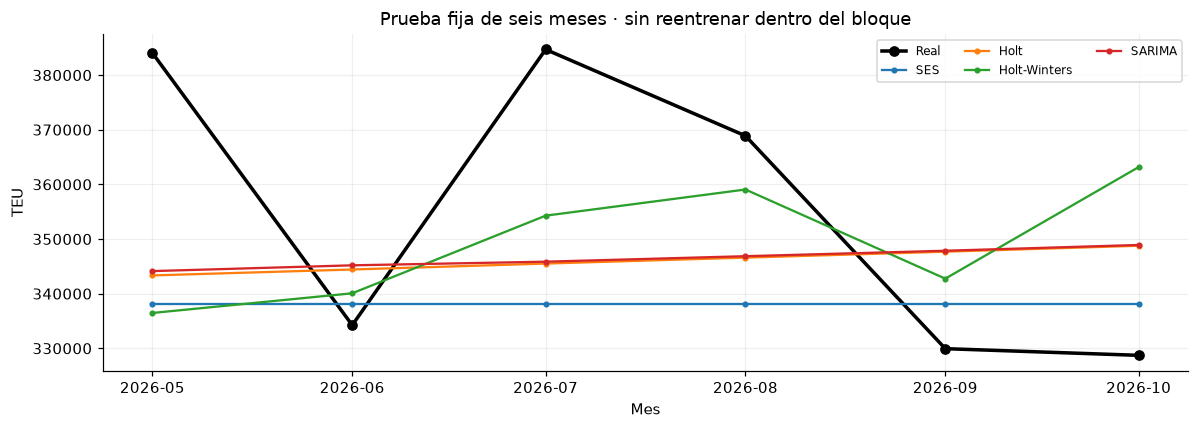

In [7]:
predicciones_prueba, filas_metricas = {}, []
for nombre, ajuste in ajustes.items():
    pred = pd.Series(np.asarray(ajuste.forecast(len(test))) * 1000, index=test.index)
    predicciones_prueba[nombre] = pred
    error = test - pred
    filas_metricas.append(
        {
            "modelo": nombre,
            "MAE": float(error.abs().mean()),
            "RMSE": float(np.sqrt(np.mean(error**2))),
            "MAPE": float(100 * np.mean(np.abs(error / test))),
        }
    )
metricas = pd.DataFrame(filas_metricas).set_index("modelo").sort_values(["MAPE", "RMSE", "MAE"])
ganador = metricas.index[0]
display(metricas.round(4))
display(
    Markdown(f"""**Ganador por MAPE: {ganador}**, con {metricas.loc[ganador, "MAPE"]:.3f}%.
El menor MAE corresponde a {metricas.MAE.idxmin()} y el menor RMSE a {metricas.RMSE.idxmin()}.
Si difieren, se conserva el criterio fijado y no se cambia la métrica después de ver el resultado.
Seis meses no representan todos los regímenes del puerto: este ranking tiene incertidumbre y no garantiza superioridad futura.""")
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(test.index, test, color="black", marker="o", linewidth=2.3, label="Real")
for nombre, pred in predicciones_prueba.items():
    ax.plot(pred.index, pred, marker=".", label=nombre)
ax.set(
    title="Prueba fija de seis meses · sin reentrenar dentro del bloque", ylabel="TEU", xlabel="Mes"
)
ax.legend(fontsize=8, ncol=3)
guardar_figura(fig, "pronostico_05_prueba_modelos.png")

## 7. Residuos del ganador y revisión de supuestos

Se reentrena la familia seleccionada con toda la serie para emitir el pronóstico, manteniendo su especificación. Para los diagnósticos se excluyen los primeros doce residuos de inicialización; se informa el tamaño restante. Ljung-Box usa rezagos 6, 12 y 24; en SARIMA se descuentan p+q+P+Q grados de libertad. En ETS se informa model_df=0 como diagnóstico orientativo, sin una equivalencia ARMA exacta. También se muestran Jarque-Bera, ARCH-LM (6 rezagos) y Levene entre las dos mitades del residuo. No rechazar no prueba que el supuesto sea verdadero.

,lb_stat,lb_pvalue
6,11.155776,0.083680
12,12.933476,0.373894
24,26.744255,0.316515


,n_residuos,model_df_LB,p_Jarque_Bera,p_ARCH_LM_6,p_Levene_mitades,razon_varianza_2a_1a
0,58,0,0.5456,0.82511,0.995013,1.084625


**Revisión honesta:**

- No se rechazaron estos diagnósticos al 5%; su potencia es limitada y no validan por sí solos cobertura del 95%.
- Los intervalos son condicionales a parámetros y modelo estimados; no incorporan plenamente incertidumbre de selección ni cambios estructurales.

La varianza móvil máxima es 5.34 veces la mínima: revisar cambios locales aunque las pruebas globales no rechacen.

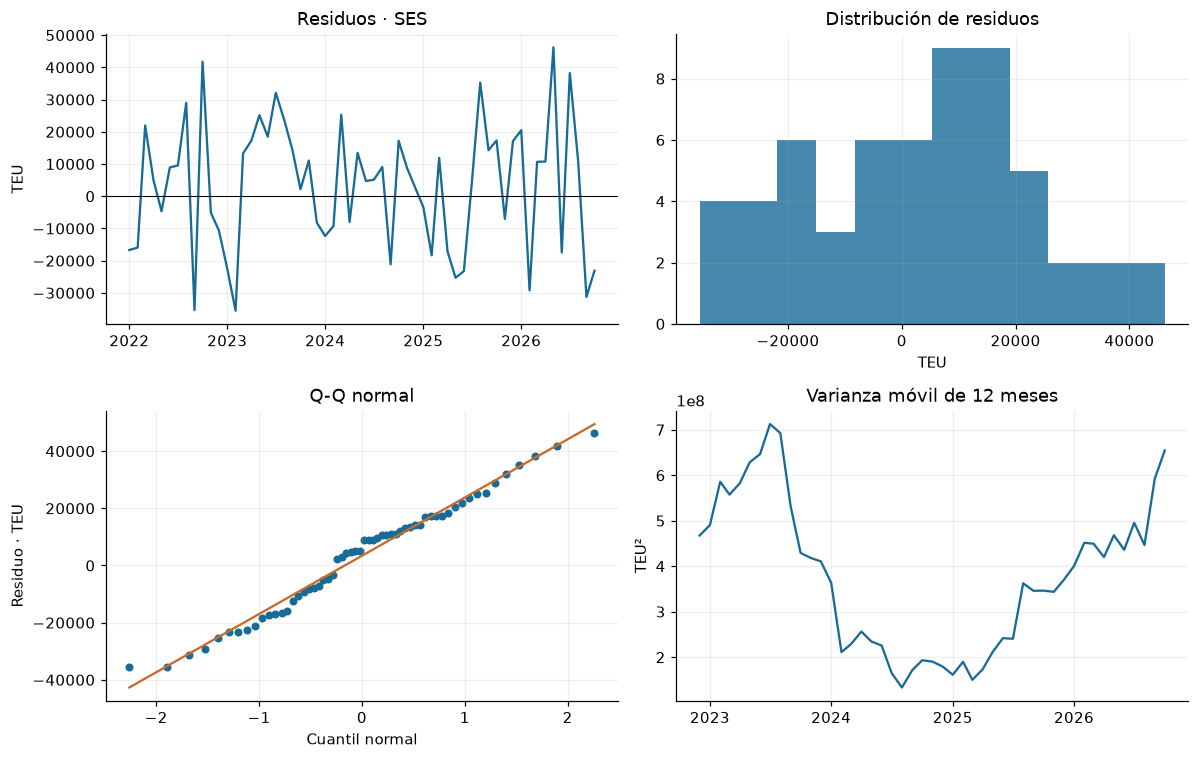

In [8]:
if ganador == "SARIMA":
    with warnings.catch_warnings(record=True) as avisos_finales:
        warnings.simplefilter("always")
        ajuste_final = SARIMAX(
            y / 1000,
            order=orden_ganador,
            seasonal_order=estacional_ganador,
            trend="c",
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(disp=False, maxiter=600)
    assert ajuste_final.mle_retvals.get("converged", False), "SARIMA final no convergió"
    df_ljung = sum(clave)
else:
    ajustes_ets = {
        "SES": (None, None),
        "Holt": ("add", None),
        "Holt-Winters": ("add", estacional_ets),
    }
    ajuste_final = ajustar_ets(y, *ajustes_ets[ganador])
    avisos_finales = []
    df_ljung = 0
burn = max(12, int(getattr(ajuste_final, "loglikelihood_burn", 0)))
residuos = pd.Series(np.asarray(ajuste_final.resid) * 1000, index=y.index).iloc[burn:].dropna()
ljung = acorr_ljungbox(residuos, lags=[6, 12, 24], model_df=df_ljung, return_df=True)
jb = st.jarque_bera(residuos)
arch = het_arch(residuos, nlags=6, ddof=df_ljung, result_object=False)
mitad = len(residuos) // 2
levene = st.levene(residuos.iloc[:mitad], residuos.iloc[mitad:], center="median")
ratio_varianza = float(residuos.iloc[mitad:].var(ddof=1) / residuos.iloc[:mitad].var(ddof=1))
display(ljung)
display(
    pd.DataFrame(
        [
            {
                "n_residuos": len(residuos),
                "model_df_LB": df_ljung,
                "p_Jarque_Bera": float(jb.pvalue),
                "p_ARCH_LM_6": float(arch[1]),
                "p_Levene_mitades": float(levene.pvalue),
                "razon_varianza_2a_1a": ratio_varianza,
            }
        ]
    )
)
advertencias_intervalo = []
if ljung.lb_pvalue.lt(0.05).any():
    advertencias_intervalo.append(
        "Ljung-Box rechaza ausencia de autocorrelación en al menos un rezago: puede quedar dependencia sin modelar."
    )
if jb.pvalue < 0.05:
    advertencias_intervalo.append(
        "Jarque-Bera rechaza normalidad: las colas pueden diferir de la distribución usada para el intervalo."
    )
if arch[1] < 0.05 or levene.pvalue < 0.05:
    advertencias_intervalo.append(
        "ARCH o Levene detecta variación de varianza: un intervalo de varianza constante puede quedar mal calibrado."
    )
if not advertencias_intervalo:
    advertencias_intervalo.append(
        "No se rechazaron estos diagnósticos al 5%; su potencia es limitada y no validan por sí solos cobertura del 95%."
    )
advertencias_intervalo.append(
    "Los intervalos son condicionales a parámetros y modelo estimados; no incorporan plenamente incertidumbre de selección ni cambios estructurales."
)
display(Markdown("**Revisión honesta:**\n\n" + "\n".join("- " + a for a in advertencias_intervalo)))
var_movil = residuos.rolling(12, min_periods=12).var().dropna()
razon_var_movil = float(var_movil.max() / var_movil.min())
if razon_var_movil > 2:
    advertencias_intervalo.append(
        f"La varianza móvil máxima es {razon_var_movil:.2f} veces la mínima: revisar cambios locales aunque las pruebas globales no rechacen."
    )
    display(Markdown(advertencias_intervalo[-1]))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(residuos.index, residuos, color=AZUL)
axes[0, 0].axhline(0, color="black", linewidth=0.7)
axes[0, 0].set(title=f"Residuos · {ganador}", ylabel="TEU")
axes[0, 1].hist(residuos, bins=12, color=AZUL, alpha=0.8)
axes[0, 1].set(title="Distribución de residuos", xlabel="TEU")
cuantiles = st.probplot(residuos, dist="norm")
axes[1, 0].scatter(cuantiles[0][0], cuantiles[0][1], color=AZUL, s=18)
axes[1, 0].plot(cuantiles[0][0], cuantiles[1][0] * cuantiles[0][0] + cuantiles[1][1], color=NARANJA)
axes[1, 0].set(title="Q-Q normal", xlabel="Cuantil normal", ylabel="Residuo · TEU")
axes[1, 1].plot(residuos.index, residuos.rolling(12, min_periods=12).var(), color=AZUL)
axes[1, 1].set(title="Varianza móvil de 12 meses", ylabel="TEU²")

axes[0, 1].xaxis.set_major_locator(MaxNLocator(5))
axes[1, 1].xaxis.set_major_locator(mdates.YearLocator())
axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

guardar_figura(fig, "pronostico_06_residuos.png")

## 8. Pronóstico de tres meses · intervalo nominal del 95%

Se utilizan los 70 meses para reestimar parámetros de la especificación ganadora, sin volver a buscar un ganador sobre la muestra completa. El intervalo corresponde a **una observación futura mensual**, no a la media ni a una banda simultánea para los tres meses. Es nominal y condicional; los diagnósticos anteriores delimitan su interpretación.

,fecha,tipo,valor,li_95,ls_95,modelo
0,2026-11-01,pronostico,344909.3,307549.9,382268.6,SES
1,2026-12-01,pronostico,344909.3,305908.8,383909.7,SES
2,2027-01-01,pronostico,344909.3,304333.9,385484.6,SES


**Para la transportista:** Con los datos publicados hasta octubre de 2026, estimamos 344,909 TEU para noviembre de 2026; el intervalo nominal del 95% va de 307,550 a 382,269 TEU, bajo los supuestos del modelo. Es una referencia de incertidumbre para planear capacidad del puerto, no una garantía ni el volumen de tu empresa; combínala con los avisos de tus clientes y revisa las alertas de residuos.

El primer mes pronosticado es 2026-11, siguiente al último publicado (2026-10); puede estar ya en curso cuando se consulte.

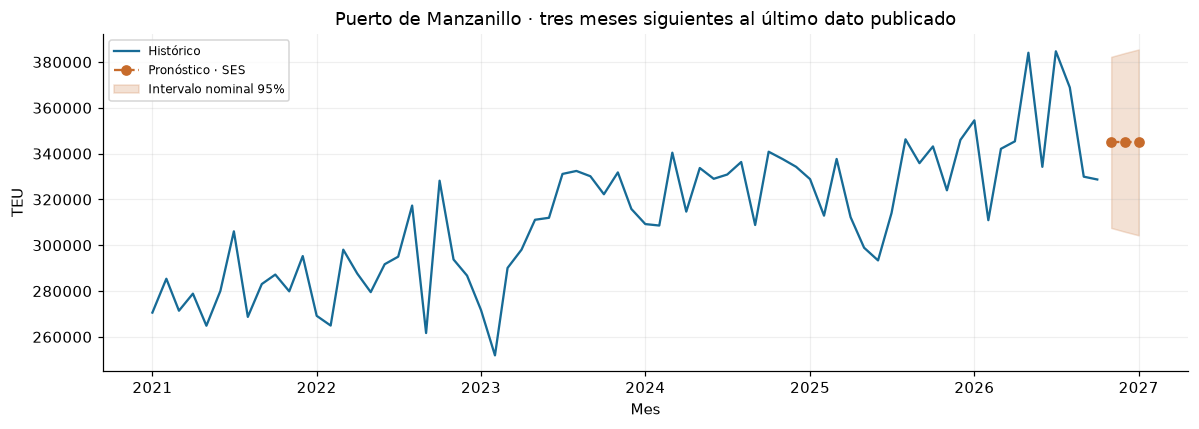

In [9]:
fechas_futuras = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=3, freq="MS")
if ganador == "SARIMA":
    pred_final = ajuste_final.get_forecast(steps=3)
    puntos = np.asarray(pred_final.predicted_mean) * 1000
    limites = np.asarray(pred_final.conf_int(alpha=0.05)) * 1000
    metodo_intervalo = (
        "SARIMA: predicción gaussiana por espacio de estados, parámetros estimados fijos"
    )
else:
    usa_simulacion = ganador == "Holt-Winters" and estacional_ets == "mul"
    opciones = (
        {"method": "simulated", "simulate_repetitions": 20000, "rng": np.random.default_rng(SEED)}
        if usa_simulacion
        else {"method": "exact"}
    )
    tabla_pred = ajuste_final.get_prediction(
        start=len(y), end=len(y) + 2, **opciones
    ).summary_frame(alpha=0.05)
    puntos = np.asarray(tabla_pred["mean"]) * 1000
    limites = tabla_pred[["pi_lower", "pi_upper"]].to_numpy() * 1000
    metodo_intervalo = (
        "ETS: simulación gaussiana (20000 réplicas)"
        if usa_simulacion
        else "ETS aditivo: intervalo analítico gaussiano de predicción"
    )
futuro = pd.DataFrame(
    {
        "fecha": fechas_futuras,
        "tipo": "pronostico",
        "valor": puntos,
        "li_95": limites[:, 0],
        "ls_95": limites[:, 1],
        "modelo": ganador,
    }
)
assert np.isfinite(futuro[["valor", "li_95", "ls_95"]]).all().all()
assert futuro.li_95.le(futuro.valor).all() and futuro.valor.le(futuro.ls_95).all()
presentacion = futuro.copy()
presentacion[["valor", "li_95", "ls_95"]] = presentacion[["valor", "li_95", "ls_95"]].round(1)
display(presentacion)
meses_es = [
    "enero",
    "febrero",
    "marzo",
    "abril",
    "mayo",
    "junio",
    "julio",
    "agosto",
    "septiembre",
    "octubre",
    "noviembre",
    "diciembre",
]
primero = futuro.iloc[0]
frase_cliente = (
    f"Con los datos publicados hasta {meses_es[y.index[-1].month - 1]} de {y.index[-1].year}, "
    f"estimamos {primero.valor:,.0f} TEU para {meses_es[primero.fecha.month - 1]} de {primero.fecha.year}; "
    f"el intervalo nominal del 95% va de {primero.li_95:,.0f} a {primero.ls_95:,.0f} TEU, bajo los supuestos del modelo. "
    "Es una referencia de incertidumbre para planear capacidad del puerto, no una garantía ni el volumen de tu empresa; "
    "combínala con los avisos de tus clientes y revisa las alertas de residuos."
)
display(Markdown("**Para la transportista:** " + frase_cliente))
display(
    Markdown(
        f"El primer mes pronosticado es {fechas_futuras[0]:%Y-%m}, siguiente al último publicado ({y.index[-1]:%Y-%m}); puede estar ya en curso cuando se consulte."
    )
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y, color=AZUL, label="Histórico")
ax.plot(fechas_futuras, puntos, "--o", color=NARANJA, label=f"Pronóstico · {ganador}")
ax.fill_between(
    fechas_futuras,
    limites[:, 0],
    limites[:, 1],
    color=NARANJA,
    alpha=0.2,
    label="Intervalo nominal 95%",
)
ax.set(
    title="Puerto de Manzanillo · tres meses siguientes al último dato publicado",
    ylabel="TEU",
    xlabel="Mes",
)
ax.legend(fontsize=8)
guardar_figura(fig, "pronostico_07_final.png")

## 9. Exportación reproducible para el tablero

CSV exacto: `fecha,tipo,valor,li_95,ls_95,modelo`. En el histórico los dos límites están vacíos; no se presentan como bandas de observaciones ya conocidas. El JSON conserva las cuatro métricas, ganador, especificación, diagnósticos, advertencias y procedencia. Un identificador SHA-256 permite reconocer exactamente qué Oro se analizó. No se usa un archivo de ejemplo del tablero.

In [10]:
historico = pd.DataFrame(
    {
        "fecha": y.index,
        "tipo": "historico",
        "valor": y.to_numpy(),
        "li_95": np.nan,
        "ls_95": np.nan,
        "modelo": "observado",
    }
)
exportado = pd.concat([historico, futuro], ignore_index=True)
contrato = ["fecha", "tipo", "valor", "li_95", "ls_95", "modelo"]
assert (
    exportado.columns.tolist() == contrato
    and len(exportado.loc[exportado.tipo.eq("pronostico")]) == 3
)
exportado.to_csv(
    RAIZ / "data/oro/pronostico_teu.csv",
    index=False,
    date_format="%Y-%m-%d",
    float_format="%.6f",
    lineterminator="\n",
)


def registros_json(tabla):
    return json.loads(tabla.to_json(orient="records", date_format="iso", double_precision=15))


resultado = {
    "objetivo": "teu_total",
    "unidad": "TEU",
    "ganador": ganador,
    "criterio_seleccion": "MAPE; desempate RMSE y MAE",
    "modelos": {
        nombre: {k: float(v) for k, v in fila.items()} for nombre, fila in metricas.iterrows()
    },
    "entrenamiento": {
        "inicio": train.index.min().strftime("%Y-%m-%d"),
        "fin": corte.strftime("%Y-%m-%d"),
        "n": len(train),
    },
    "prueba": {
        "inicio": test.index.min().strftime("%Y-%m-%d"),
        "fin": test.index.max().strftime("%Y-%m-%d"),
        "n": len(test),
    },
    "datos_sha256": hashlib.sha256(ruta_datos.read_bytes()).hexdigest(),
    "parametros_limpieza_sha256": hashlib.sha256(ruta_parametros.read_bytes()).hexdigest(),
    "versiones": {
        p: importlib.metadata.version(p)
        for p in ["statsmodels", "pandas", "numpy", "scipy", "matplotlib"]
    },
    "caracterizacion": caracterizacion,
    "descomposicion": {
        "elegida": descomp_elegida,
        "comparacion": registros_json(tabla_decomp.reset_index()),
        "perfil_mensual": {str(k): float(v) for k, v in perfil.items()},
    },
    "adf": registros_json(tabla_adf.reset_index()),
    "acf_significativos_puntuales": lags_acf,
    "pacf_significativos_puntuales": lags_pacf,
    "ccf": {
        "convencion": "corr(delta_TEU_t filtrado, delta_X_(t-k) filtrado); k>0 predictor anticipa",
        "preblanqueo": filtros,
        "ajuste_multiple": "Holm, 50 contrastes",
        "resultados": registros_json(tabla_ccf),
    },
    "sarima": {
        "orden": list(orden_ganador),
        "orden_estacional": list(estacional_ganador),
        "tendencia": "c",
        "busqueda": registros_json(tabla_sarima),
    },
    "residuos": {
        "muestra": "reentrenamiento completo, excluidos primeros 12 o burn mayor",
        "n": len(residuos),
        "model_df_ljungbox": int(df_ljung),
        "ljungbox": registros_json(ljung.rename_axis("rezago").reset_index()),
        "jarque_bera_p": float(jb.pvalue),
        "arch_lm_6_p": float(arch[1]),
        "levene_mitades_p": float(levene.pvalue),
        "razon_varianza_segunda_primera": ratio_varianza,
        "razon_varianza_movil_max_min": razon_var_movil,
    },
    "intervalo": {
        "nivel_nominal": 0.95,
        "horizonte_meses": 3,
        "metodo": metodo_intervalo,
        "advertencias": advertencias_intervalo,
        "replicas_si_simulado": 20000 if "simulación" in metodo_intervalo else None,
    },
    "frase_cliente": frase_cliente,
    "pronostico": registros_json(futuro),
}
(RAIZ / "data/oro/pronostico_metricas.json").write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print(
    "Exportados:", RAIZ / "data/oro/pronostico_teu.csv", RAIZ / "data/oro/pronostico_metricas.json"
)
print("Filas históricas:", len(historico), "| Filas de pronóstico:", len(futuro))

Exportados: C:\Users\Colibecas\Desktop\Proyecto_Monico_Armando\data\oro\pronostico_teu.csv C:\Users\Colibecas\Desktop\Proyecto_Monico_Armando\data\oro\pronostico_metricas.json
Filas históricas: 70 | Filas de pronóstico: 3


## 10. Reproducción, referencias y límites

Desde la raíz, con el entorno de `requirements.txt` activo:

```bash
jupyter nbconvert --to notebook --execute --inplace laboratorio/E1_pronostico.ipynb --ExecutePreprocessor.timeout=1800
ruff check src tests laboratorio/E1_pronostico.ipynb
python -m pytest -q --cov=src --cov-report=term-missing
```

El notebook conserva sus salidas. No requiere datos externos ni tokens. En un entorno virtual, el kernel `python3` debe apuntar al mismo Python donde se instalaron las dependencias. La semilla fija se usa si se necesita simulación para un ETS no lineal; los modelos de intervalo analítico no requieren simulación.

Referencias primarias: [ETS y predicción](https://www.statsmodels.org/stable/generated/statsmodels.tsa.exponential_smoothing.ets.ETSResults.get_prediction.html), [SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html), [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [Ljung-Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html). Las correlaciones son exploratorias y los intervalos nominales; no se promete cobertura empírica de 19 de cada 20 meses sin una validación de cobertura adicional.

**Uso de Codex:** asistencia en programación, ejecución, gráficos y redacción. Todos los números de las interpretaciones y exportaciones se calculan en esta ejecución. Los registros PSP y el consentimiento del transportista nacional se completan únicamente con la confirmación de Gabriel; no se asumen a partir de esta actividad.